# Level 4: Selection rules, line intensities and parameter fitting

**Goal.** Predict not only *where* the Zeeman lines are but also *how bright* and *how polarised*
they are, then fit a parameter back from "measured" data.

**Physics.** The electric-dipole operator is a rank-1 spherical tensor. By the Wigner-Eckart theorem
its matrix elements are proportional to a Wigner 3-j symbol:
$$\langle l'm'|C^{(1)}_q|l\,m\rangle = (-1)^{m'}\sqrt{(2l+1)(2l'+1)}
\begin{pmatrix} l' & 1 & l\\ 0&0&0\end{pmatrix}
\begin{pmatrix} l' & 1 & l\\ -m' & q & m\end{pmatrix}.$$
This enforces $\Delta l = \pm1$ and $m' - m = q \in \{-1,0,+1\}$ ($q=0$: $\pi$ light, $q=\pm1$: $\sigma$).
Intensities are the squared matrix elements between the exact eigenstates of each level.

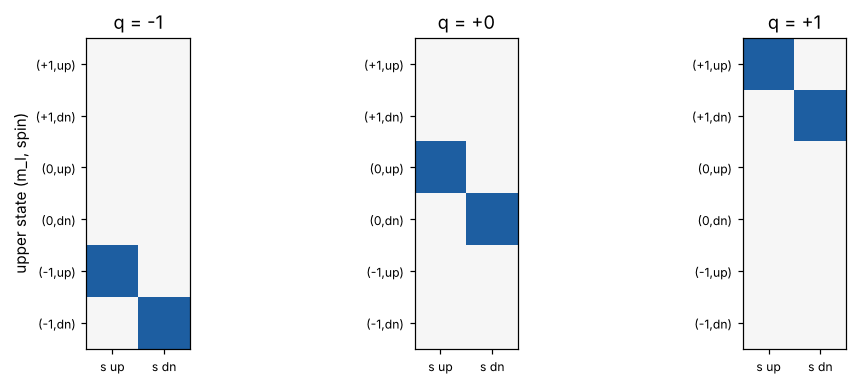

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
from src.transitions import dipole_matrices

d = dipole_matrices(1, 0)          # upper l=1 (6 states) to lower l=0 (2 states)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, q in zip(axes, (-1, 0, 1)):
    im = ax.imshow(d[q], cmap='RdBu', vmin=-0.7, vmax=0.7)
    ax.set_title('q = %+d' % q)
    ax.set_yticks(range(6)); ax.set_yticklabels(['(+1,up)', '(+1,dn)', '(0,up)', '(0,dn)', '(-1,up)', '(-1,dn)'], fontsize=8)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['s up', 's dn'], fontsize=8)
    ax.grid(False)
axes[0].set_ylabel('upper state (m_l, spin)')
plt.tight_layout(); plt.show()

Each panel is the dipole operator for one polarisation. Only one orbital row is non-zero per $q$
(selection rule $\Delta m = q$) and spin is never flipped (blocks are diagonal in spin).

## Sodium D lines: positions, polarisation, intensities

In [2]:
from src.validation import zeta_from_fine_structure
from src.transitions import zeeman_lines
from src.animation import plot_stick_spectrum
from src.constants import MU_B_EV, wavenumber_to_ev, ev_to_wavenumber

zeta = zeta_from_fine_structure(17.196, l=1)
gap = wavenumber_to_ev(16956.17) + zeta           # measured Na D1 sets the energy origin
d1c, d2c = gap - zeta, gap + zeta / 2
B = 0.05                                          # weak field so the textbook patterns are clean
df = zeeman_lines(1, 0, B, zeta, 0.0, gap)
mid = 0.5 * (d1c + d2c)

for name, centre, sel in (('D1', d1c, df.energy_ev < mid), ('D2', d2c, df.energy_ev >= mid)):
    sub = df[sel].copy()
    sub['shift (mu_B B)'] = (sub.energy_ev - centre) / (MU_B_EV * B)
    print(name, '  components:', len(sub), '  total intensity: %.3f' % sub.intensity.sum())
    print(sub[['polarisation', 'shift (mu_B B)', 'intensity']].round(3).to_string(index=False))
    print()

ratio = df[df.energy_ev >= mid].intensity.sum() / df[df.energy_ev < mid].intensity.sum()
print('D2 : D1 intensity ratio = %.4f   (statistical weights 4 : 2 -> 2)' % ratio)

D1   components: 4   total intensity: 2.000
polarisation  shift (mu_B B)  intensity
      sigma-          -1.334      0.666
          pi          -0.669      0.333
          pi           0.668      0.334
      sigma+           1.334      0.667

D2   components: 6   total intensity: 4.000
polarisation  shift (mu_B B)  intensity
      sigma-          -1.668      0.334
      sigma-          -1.000      1.000
          pi          -0.334      0.667
          pi           0.334      0.666
      sigma+           1.000      1.000
      sigma+           1.669      0.333

D2 : D1 intensity ratio = 2.0000   (statistical weights 4 : 2 -> 2)


Textbook values for sodium (LS coupling): D1 lines at $\pm\tfrac23$ ($\pi$) and $\pm\tfrac43$ ($\sigma$)
in units of $\mu_B B$ with relative intensities $1:2$; D2 lines at $\pm\tfrac13$ ($\pi$), $\pm1$ ($\sigma$),
$\pm\tfrac53$ ($\sigma$) with intensities $2:3:1$. The numbers above reproduce all of it, with no
pattern typed in by hand. They come purely from diagonalising $H$ and applying the dipole operator.

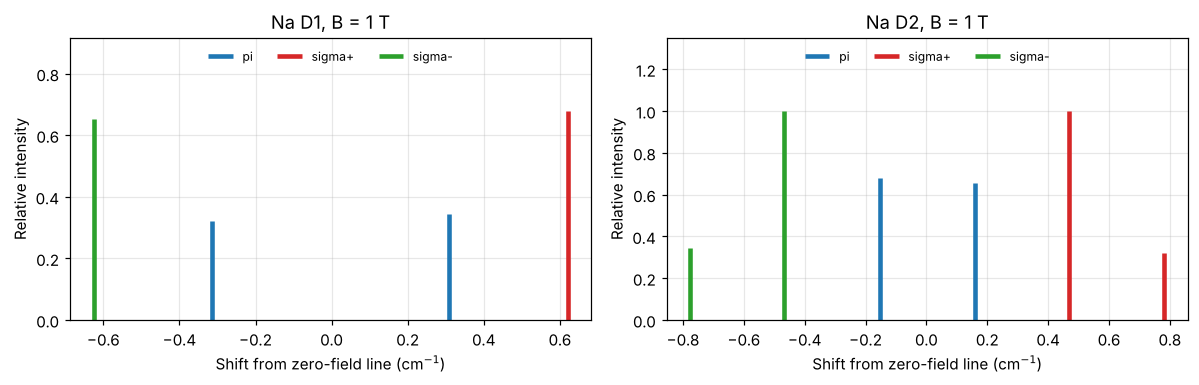

In [3]:
df1 = zeeman_lines(1, 0, 1.0, zeta, 0.0, gap)
mid = 0.5 * (d1c + d2c)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_stick_spectrum(df1[df1.energy_ev < mid], ev_to_wavenumber(d1c), axes[0], 'Na D1, B = 1 T')
plot_stick_spectrum(df1[df1.energy_ev >= mid], ev_to_wavenumber(d2c), axes[1], 'Na D2, B = 1 T')
plt.tight_layout(); plt.show()

## Fitting a parameter back from data

In a real experiment you measure energies and want the physical constants. Here we create
synthetic "measurements" with a known $\zeta$ and 1 micro-eV noise, then recover it with
`src.fitting.fit_parameters` (SciPy least squares), starting from a deliberately wrong guess.

In [4]:
from src.fitting import fit_parameters
from src.solvers import energy_vs_field

rng = np.random.default_rng(1)
bs = np.linspace(1, 40, 15)
data = energy_vs_field(1, bs, zeta) + rng.normal(0, 1e-6, size=(bs.size, 6))   # eV

res = fit_parameters(1, bs, data, zeta0_ev=2.0 * zeta)                         # start 2x too large
print('true zeta  = %.6f eV' % zeta)
print('fitted     = %.6f eV   (relative error %.3f %%)' % (res.zeta_ev, 100 * (res.zeta_ev - zeta) / zeta))
print('rms residual = %.2e eV' % res.rms_residual_ev)

res2 = fit_parameters(1, bs, data, zeta0_ev=zeta, g_s0=2.0, fit_g_s=True)
print('fit with g_s free:  zeta = %.6f eV,  g_s = %.5f  (true g_s = 2.00232)' % (res2.zeta_ev, res2.g_s))

true zeta  = 0.001421 eV
fitted     = 0.001421 eV   (relative error 0.007 %)
rms residual = 8.40e-07 eV
fit with g_s free:  zeta = 0.001422 eV,  g_s = 2.00212  (true g_s = 2.00232)


## Optional: the same fit with PyTorch autograd

`src/torch_engine.py` does the same job with automatic differentiation. It needs PyTorch
(`pip install torch`), which is optional for this project.

In [5]:
try:
    from src.torch_engine import fit_zeta
    z_torch = fit_zeta(1, bs, data, zeta0=1e-3)
    print('torch fit zeta = %.6f eV   (scipy fit = %.6f eV)' % (z_torch, res.zeta_ev))
except ImportError:
    print('PyTorch is not installed here, so this optional cell is skipped.')

PyTorch is not installed here, so this optional cell is skipped.


**Take-away.** Level 4 completes the chain: Hamiltonian, then energies, then transition
amplitudes, then a full predicted spectrum with polarisation and intensity. Matching the known sodium
pattern is the strongest evidence in the project that the model is right. The fitting step shows how
the same machinery works in reverse to extract constants from data.